In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = Path("../raw/satellite_samples")

print("Folder exists:", IMAGE_DIR.exists())

if IMAGE_DIR.exists():
    print("Files:", list(IMAGE_DIR.iterdir()))

Folder exists: True
Files: [WindowsPath('../raw/satellite_samples/insat_cyclone_sample.jpg')]


Filename: insat_cyclone_sample.jpg
Image size: (2002, 2242)
Image mode: RGB
Image format: JPEG


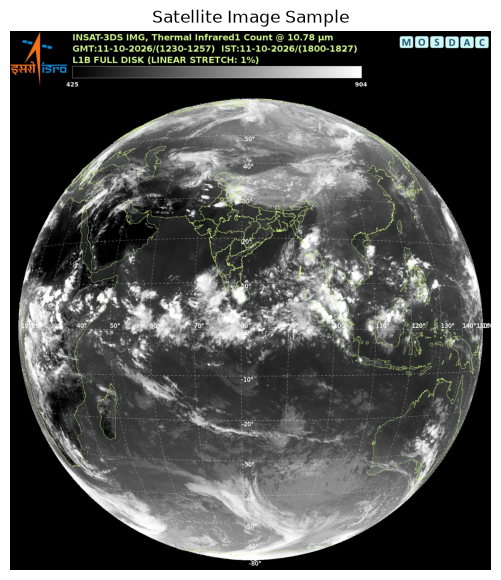

In [2]:
image_files = [
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]
]

if image_files:
    image_path = image_files[0]
    image = Image.open(image_path)

    print("Filename:", image_path.name)
    print("Image size:", image.size)
    print("Image mode:", image.mode)
    print("Image format:", image.format)

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title("Satellite Image Sample")
    plt.axis("off")
    plt.show()
else:
    print("No supported image files found.")

In [3]:
image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Array shape: (2242, 2002, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [4]:
print("Image shape:", image_array.shape)

if image_array.ndim == 2:
    print("Grayscale image")
elif image_array.ndim == 3:
    print("Number of channels:", image_array.shape[2])
else:
    print("Unexpected image dimensions")

Image shape: (2242, 2002, 3)
Number of channels: 3


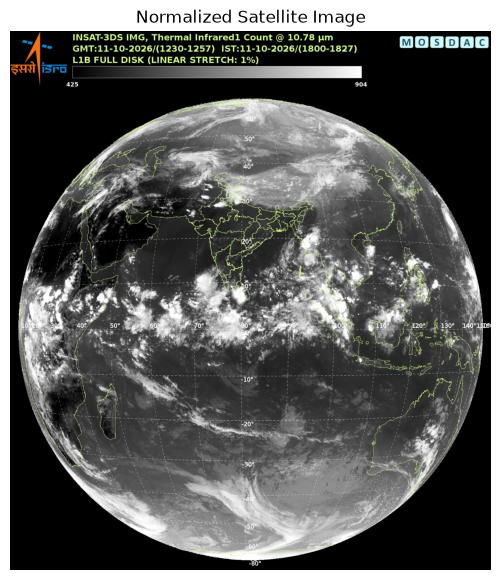

In [5]:
image_float = image_array.astype(np.float32)

image_normalized = (
    (image_float - image_float.min()) /
    (image_float.max() - image_float.min() + 1e-8)
)

plt.figure(figsize=(10, 7))
plt.imshow(image_normalized, cmap="gray" if image_array.ndim == 2 else None)
plt.title("Normalized Satellite Image")
plt.axis("off")
plt.show()

In [6]:
print("Image dimensions:", image.size)
print("Array data type:", image_array.dtype)
print("Minimum value:", image_array.min())
print("Maximum value:", image_array.max())
print("Mean pixel value:", round(float(image_array.mean()), 2))
print("Standard deviation:", round(float(image_array.std()), 2))

Image dimensions: (2002, 2242)
Array data type: uint8
Minimum value: 0
Maximum value: 255
Mean pixel value: 73.76
Standard deviation: 73.43


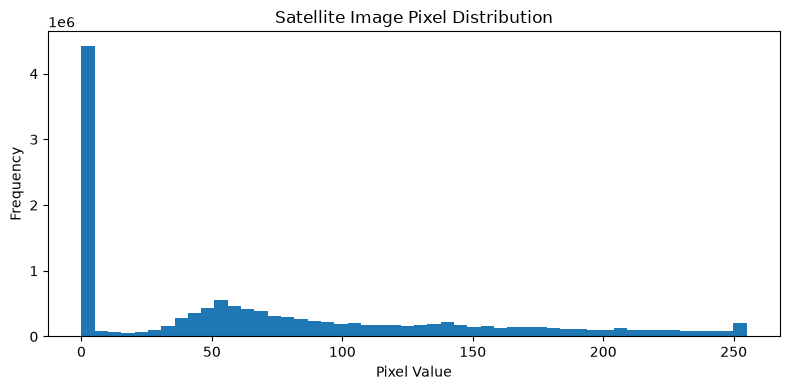

In [7]:
plt.figure(figsize=(8, 4))

plt.hist(image_array.ravel(), bins=50)

plt.title("Satellite Image Pixel Distribution")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [8]:
# Calculate contrast using pixel intensity standard deviation
contrast = image_array.std()

print(f"Image contrast (standard deviation): {contrast:.2f}")

if contrast < 30:
    print("The image may have relatively low contrast.")
else:
    print("The image has a reasonable intensity variation.")

Image contrast (standard deviation): 73.43
The image has a reasonable intensity variation.


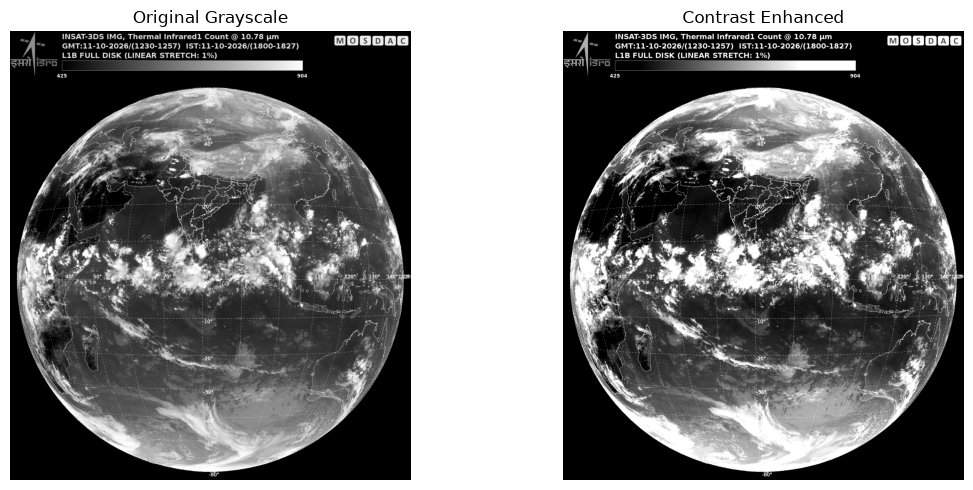

In [11]:
from PIL import Image, ImageEnhance
import numpy as np
import matplotlib.pyplot as plt

# Load the image again
IMAGE_DIR = Path("../raw/satellite_samples")

image_files = [
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]
]

if not image_files:
    print("No image found in satellite_samples.")
else:
    image_path = image_files[0]
    image = Image.open(image_path)

    # Convert to grayscale
    gray = image.convert("L")

    # Enhance contrast
    enhanced = ImageEnhance.Contrast(gray).enhance(1.5)

    # Display comparison
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(gray, cmap="gray")
    plt.title("Original Grayscale")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(enhanced, cmap="gray")
    plt.title("Contrast Enhanced")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [13]:
print("Filename:", image_path.name)
print("Format:", image.format)
print("Dimensions:", image.size)
print("Color mode:", image.mode)
print("File size (KB):", round(image_path.stat().st_size / 1024, 2))

print("\nImage metadata:")
print(image.info)

Filename: insat_cyclone_sample.jpg
Format: JPEG
Dimensions: (2002, 2242)
Color mode: RGB
File size (KB): 696.88

Image metadata:
{'jfif': 257, 'jfif_version': (1, 1), 'jfif_unit': 0, 'jfif_density': (1, 1)}


In [14]:
import numpy as np

gray_array = np.array(gray)

print("Array shape:", gray_array.shape)
print("Data type:", gray_array.dtype)
print("Minimum intensity:", gray_array.min())
print("Maximum intensity:", gray_array.max())
print("Mean intensity:", round(float(gray_array.mean()), 2))
print("Intensity standard deviation:", round(float(gray_array.std()), 2))

Array shape: (2242, 2002)
Data type: uint8
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 74.23
Intensity standard deviation: 73.82


## Image Assessment and Limitations

### Observations
- The sample is an INSAT-3DS thermal infrared image at 10.78 μm.
- The image was inspected for dimensions, pixel values, and intensity distribution.
- Grayscale conversion and contrast enhancement were explored.
- Basic image metadata and pixel statistics were examined.

### Limitations
- The sample is a gallery image with labels and geographic overlays.
- It is not confirmed to be raw scientific satellite data.
- A single image cannot represent cyclone evolution over time.
- No cyclone-specific ground-truth labels or segmentation masks are available.

### Requirements for Future Modelling
- Multiple timestamped satellite observations.
- Consistent image formats and spectral channels.
- Geographic and temporal metadata.
- Historical cyclone tracks for comparison.
- Suitable labels for classification or segmentation.

### Conclusion
This sample helped establish the initial image inspection and preprocessing workflow.
A larger, consistent satellite dataset is required before training or evaluating
cyclone classification, segmentation, or trajectory prediction models.

In [16]:
from pathlib import Path

OUTPUT_DIR = Path("../processed/satellite_samples")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "insat_cyclone_grayscale.png"
gray.save(output_path)

print("Processed image saved to:", output_path)
print("File exists:", output_path.exists())

Processed image saved to: ..\processed\satellite_samples\insat_cyclone_grayscale.png
File exists: True


In [17]:
print("Processed image exists:", output_path.exists())
print("Saved at:", output_path)

Processed image exists: True
Saved at: ..\processed\satellite_samples\insat_cyclone_grayscale.png
